## Code is meant to make sure the nist data we are pulling aligns with what we are seeing

In [1]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openpyxl
import seaborn as sns
from pathlib import Path

In [2]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_seq_items", None)

# numpy: show full arrays
np.set_printoptions(threshold=np.inf, linewidth=np.inf, precision=6, suppress=True)

In [3]:
#file preprocessing:

#opening file
filename='/Users/bigdawg/Library/CloudStorage/Box-Box/LIBS!/Spectral library/Raw Spectra/4:19:2026/zenodo.10K_VACUUM.7.2mJ.csv'
raw=pd.read_csv(filename,low_memory=False)

#renaming to easier columns
wavelength_name=raw.iloc[0,10:].values

raw=raw.drop(index=0)
raw=raw.reset_index(drop=True)

#renaming first row to be the real compunds 
raw.columns=['sample_id', 'SiO2', 'TiO2', 'Al2O3', 'Fe2O3', 'MgO', 'CaO', 'Na2O', 'K2O', 'Pellet Name'] + [float(x) for x in wavelength_name]

ELEMENTS=['SiO2','TiO2', 'Al2O3', 'Fe2O3', 'MgO', 'CaO', 'Na2O', 'K2O']

#creating df of just wavelengths, each row corresponds to same sample
wavelength_cols=raw.columns[10:]
spectra=raw[wavelength_cols].astype(float)

for el in ELEMENTS:
    raw[el]=pd.to_numeric(raw[el],errors='coerce')




print(f'Loaded {len(raw)} spectra with {len(wavelength_cols)} wavelength channels')
print(f'Wavelength range: {wavelength_cols[0]:.2f} to {wavelength_cols[-1]:.2f} nm')
print(f'Available elements: {ELEMENTS}')


Loaded 2503 spectra with 15498 wavelength channels
Wavelength range: 240.86 to 859.41 nm
Available elements: ['SiO2', 'TiO2', 'Al2O3', 'Fe2O3', 'MgO', 'CaO', 'Na2O', 'K2O']


# Removing total weight % outliers

In [4]:
#putting total composition after K2O
raw['total_oxides'] = raw[ELEMENTS].sum(axis=1)
col = raw.pop('total_oxides')
raw.insert(raw.columns.get_loc('K2O') + 1, 'total_oxides', col)
print(raw.columns)

compCols=ELEMENTS + ['total_oxides']


Index([   'sample_id',         'SiO2',         'TiO2',        'Al2O3',
              'Fe2O3',          'MgO',          'CaO',         'Na2O',
                'K2O', 'total_oxides',  'Pellet Name',    240.8587919,
          240.8920957,     240.925399,    240.9587019,    240.9920041,
          241.0253059,    241.0586071,    241.0919078,     241.125208,
          241.1585076,    241.1918067,    241.2251053,    241.2584034,
          241.2917009,    241.3249979,    241.3582943,    241.3915903,
          241.4248857,    241.4581805,    241.4914748,    241.5247686,
          241.5580619,    241.5913546,    241.6246468,    241.6579384,
          241.6912296,    241.7245201,    241.7578102,    241.7910997,
          241.8243886,    241.8576771,    241.8909649,    241.9242523,
          241.9575391,    241.9908254,    242.0241111,    242.0573963,
          242.0906809,     242.123965,    242.1572486,    242.1905316,
           242.223814,     242.257096,    242.2903773,    242.3236582,
      

/var/folders/p1/zrd1bsr50ss60kshx0hm44j80000gn/T/ipykernel_36085/2141590876.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw['total_oxides'] = raw[ELEMENTS].sum(axis=1)
/var/folders/p1/zrd1bsr50ss60kshx0hm44j80000gn/T/ipykernel_36085/2141590876.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw.insert(raw.columns.get_loc('K2O') + 1, 'total_oxides', col)


In [5]:
rawTotComp=raw.copy()
colsToRemove=rawTotComp[rawTotComp['total_oxides']>105].index
print(f'num samples with total oxides >105%: {len(colsToRemove)}')
rawTotComp=rawTotComp.drop(colsToRemove).reset_index(drop=True)

colsToRemove=rawTotComp[rawTotComp['total_oxides']<96].index
print(f'num samples with total oxides <96%: {len(colsToRemove)}')
rawTotComp=rawTotComp.drop(colsToRemove).reset_index(drop=True)



num samples with total oxides >105%: 15
num samples with total oxides <96%: 305


In [6]:

comp_stats = raw[compCols].agg(['mean', 'std']).T

# optional: nicer column names
comp_stats.columns = ['average', 'stdev']

print(f'comp stats with all samples:\n{comp_stats}')


comp_stats = rawTotComp[compCols].agg(['mean', 'std']).T

# optional: nicer column names
comp_stats.columns = ['average', 'stdev']

print(f'comp stats with 96-105 window:\n{comp_stats}')

comp stats with all samples:
                average      stdev
SiO2          57.841746  13.434021
TiO2           1.313035   1.171447
Al2O3         13.558773   4.429121
Fe2O3          8.261901   5.116116
MgO            5.927628   6.864870
CaO            6.251224   5.497922
Na2O           2.716738   1.428350
K2O            2.135417   2.193399
total_oxides  98.006461   5.293868
comp stats with 96-105 window:
                average      stdev
SiO2          58.658893  12.489626
TiO2           1.303084   1.014400
Al2O3         13.710703   3.619425
Fe2O3          8.463426   4.929480
MgO            5.862930   6.511976
CaO            6.253284   4.539447
Na2O           2.877076   1.354556
K2O            2.099979   2.139868
total_oxides  99.229374   0.865171


# Removing based on compositional outliers

In [7]:
df = rawTotComp.copy()

df["is_outlier"]=False
df["outlier_reason"] = ""

In [8]:
avgSiO2 = df["SiO2"].mean()
stdSiO2 = df["SiO2"].std()

threshold=avgSiO2 -2*stdSiO2
print(f'threshold for SiO2 outliers: {threshold:.2f}')
outliers = df[df["SiO2"] < threshold]
print(f'num outliers identified for SiO2: {len(outliers)}')
df.loc[outliers.index, "is_outlier"] = True
df.loc[outliers.index, "outlier_reason"] = "Low SiO2"


threshold for SiO2 outliers: 33.68
num outliers identified for SiO2: 0


In [9]:
threshold=0.01
print(f'threshold for MgO outliers: {threshold:.2f}')
outliers = df[df["MgO"] < threshold]
print(f'num outliers identified for MgO: {len(outliers)}')
df.loc[outliers.index, "is_outlier"] = True
df.loc[outliers.index, "outlier_reason"] = "Low MgO"

threshold for MgO outliers: 0.01
num outliers identified for MgO: 56


In [10]:
avgTiO2 = df["TiO2"].mean()
stdTiO2 = df["TiO2"].std()

threshold=10
print(f'threshold for TiO2 outliers: {threshold:.2f}')
outliers = df[df["TiO2"] > threshold]
print(f'num outliers identified for TiO2: {len(outliers)}')
df.loc[outliers.index, "is_outlier"] = True
df.loc[outliers.index, "outlier_reason"] = "High TiO2"


threshold for TiO2 outliers: 10.00
num outliers identified for TiO2: 0


In [11]:
avgFe2O3 = df["Fe2O3"].mean()
stdFe2O3 = df["Fe2O3"].std()

threshold=20
print(f'threshold for Fe2O3 outliers: {threshold:.2f}')
outliers = df[df["Fe2O3"] > threshold]
print(f'num outliers identified for Fe2O3: {len(outliers)}')
df.loc[outliers.index, "is_outlier"] = True
df.loc[outliers.index, "outlier_reason"] = "High Fe2O3"


threshold for Fe2O3 outliers: 20.00
num outliers identified for Fe2O3: 0


In [12]:
avgCaO = df["CaO"].mean()
stdCaO = df["CaO"].std()

threshold=avgCaO +2.5*stdCaO
print(f'threshold for CaO outliers: {threshold:.2f}')
outliers = df[df["CaO"] > threshold]
print(f'num outliers identified for CaO: {len(outliers)}')
df.loc[outliers.index, "is_outlier"] = True
df.loc[outliers.index, "outlier_reason"] = "High CaO"


threshold for CaO outliers: 17.60
num outliers identified for CaO: 16


In [13]:
avgNa2O = df["Na2O"].mean()
stdNa2O = df["Na2O"].std()

threshold=avgNa2O +2*stdNa2O
print(f'threshold for Na2O outliers: {threshold:.2f}')
outliers = df[df["Na2O"] > threshold]
print(f'num outliers identified for Na2O: {len(outliers)}')
df.loc[outliers.index, "is_outlier"] = True
df.loc[outliers.index, "outlier_reason"] = "High Na2O"


threshold for Na2O outliers: 5.59
num outliers identified for Na2O: 58


## Normalizing over wavelength ranges: 
This method of normalization has been extensively tested
beginning with Tucker et al. (2010), K. H. Lepore et al. (2017), Rapin et al. (2017), Thomas et al. (2018), and
especially Ytsma and Dyar (2018). 

In [14]:
#normalization 

def normalize_spectra(spectra):
    UV_cols = [col for col in spectra.columns if 240.81 <= col <= 351.35]
    VIS_cols = [col for col in spectra.columns if 370.16 <= col <= 479.07]
    VNIR_cols = [col for col in spectra.columns if 508.30 <= col <= 859.46]

    totUV = spectra[UV_cols].sum(axis=1).replace(0, np.nan)
    totVIS = spectra[VIS_cols].sum(axis=1).replace(0, np.nan)
    totVNIR = spectra[VNIR_cols].sum(axis=1).replace(0, np.nan)

    spectra_norm = spectra.copy()
    spectra_norm[UV_cols] = spectra[UV_cols].div(totUV, axis=0)
    spectra_norm[VIS_cols] = spectra[VIS_cols].div(totVIS, axis=0)
    spectra_norm[VNIR_cols] = spectra[VNIR_cols].div(totVNIR, axis=0)

    return spectra_norm

In [15]:
df_no_outlier = df[df['is_outlier']==False].reset_index(drop=True)

X = normalize_spectra(df_no_outlier[wavelength_cols].astype(float)).values
Y = df_no_outlier[ELEMENTS].values
groups = df_no_outlier.groupby(ELEMENTS).ngroup().values

print(X.shape, Y.shape, len(np.unique(groups)))

(2053, 15498) (2053, 8) 1964


## Here begins the analysis

In [17]:
TOP3_SHARE = 95   # the 3 largest oxides must make up at least this % of the total

comp = df_no_outlier[ELEMENTS]
top3Share = np.sort(comp.values, axis=1)[:, -3:].sum(axis=1) / comp.sum(axis=1).values * 100
top3Names = comp.apply(lambda row: '+'.join(sorted(row.nlargest(3).index, key=ELEMENTS.index)), axis=1)

keep = top3Share >= TOP3_SHARE
simple = df_no_outlier[keep].copy()
simple['top3'] = top3Names[keep]
simple['top3 %'] = top3Share[keep].round(1)

print(len(simple), 'samples where 3 oxides make up >=', TOP3_SHARE, '% of the total')
print(simple['top3'].value_counts())
display(simple[['Pellet Name', 'top3', 'top3 %'] + ELEMENTS].round(2))

109 samples where 3 oxides make up >= 95 % of the total
top3
SiO2+Al2O3+K2O      57
SiO2+Al2O3+Na2O     23
SiO2+Al2O3+Fe2O3    15
SiO2+TiO2+Fe2O3      8
SiO2+Al2O3+CaO       3
SiO2+Al2O3+MgO       1
SiO2+TiO2+Al2O3      1
SiO2+TiO2+K2O        1
Name: count, dtype: int64


,Pellet Name,top3,top3 %,SiO2,TiO2,Al2O3,Fe2O3,MgO,CaO,Na2O,K2O
38,11KMASED004,SiO2+Al2O3+Na2O,97.7,85.71,0.40,8.41,1.23,0.14,0.09,3.77,0.41
226,9394H,SiO2+Al2O3+Na2O,96.4,76.88,0.05,13.62,0.70,0.21,0.23,4.28,2.30
262,C10MA002,SiO2+Al2O3+K2O,95.2,77.50,0.06,12.72,1.03,0.03,0.21,3.44,4.60
268,C10MA009C,SiO2+Al2O3+K2O,95.7,74.94,0.01,14.80,0.30,0.03,0.85,3.12,5.48
272,C10MA032,SiO2+Al2O3+K2O,96.1,79.32,0.05,12.21,0.53,0.01,0.07,3.20,4.75
274,C10MA034,SiO2+Al2O3+K2O,98.5,89.04,0.11,6.15,0.94,0.24,0.03,0.13,2.68
281,C11MA044A,SiO2+Al2O3+K2O,98.7,93.03,0.12,3.81,0.59,0.38,0.00,0.20,1.69
282,C11MA044B,SiO2+Al2O3+K2O,98.4,92.47,0.11,3.85,0.50,0.31,0.10,0.56,1.51
283,C11MA045,SiO2+Al2O3+CaO,95.8,89.68,0.12,3.92,0.74,1.49,1.92,0.34,1.48
291,C11MA052,SiO2+Al2O3+K2O,96.2,74.64,0.02,14.20,0.57,0.01,1.32,1.87,7.56


## Plotting samples

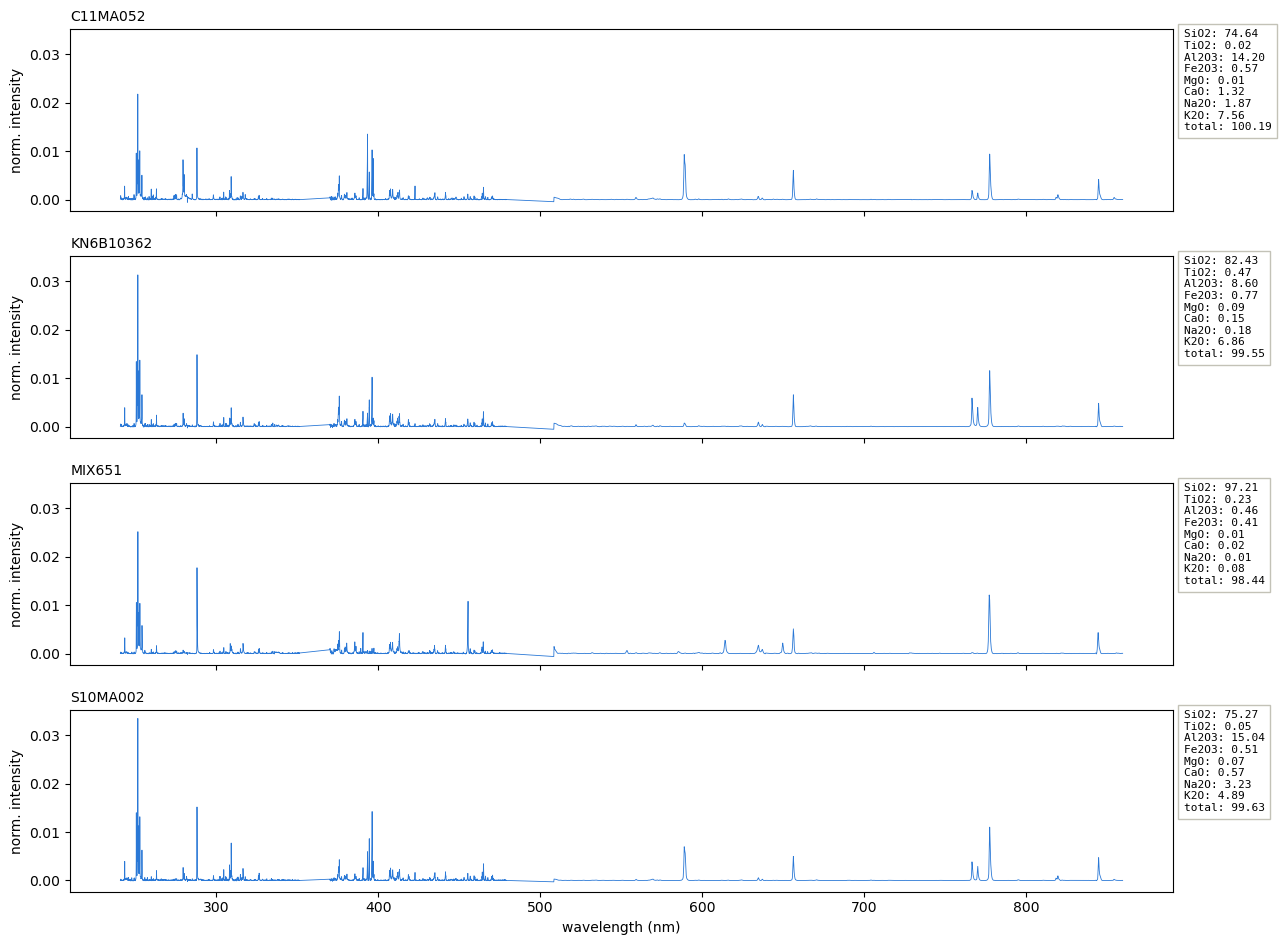

In [18]:
pellets = ['C11MA052', 'KN6B10362', 'MIX651', 'S10MA002']
wl = np.array(wavelength_cols, dtype=float)

fig, axes = plt.subplots(len(pellets), 1, figsize=(15, 2.8 * len(pellets)), sharex=True, sharey=True)

for ax, name in zip(axes, pellets):
    row = df_no_outlier.index[df_no_outlier['Pellet Name'] == name][0]
    comp = df_no_outlier.loc[row, ELEMENTS]

    ax.plot(wl, X[row], color='#2a78d6', linewidth=0.6)
    ax.set_title(name, loc='left', fontsize=10)
    ax.set_ylabel('norm. intensity')

    text = '\n'.join(f'{ox}: {comp[ox]:.2f}' for ox in ELEMENTS) + f'\ntotal: {comp.sum():.2f}'
    ax.text(1.01, 1.0, text, transform=ax.transAxes, ha='left', va='top', fontsize=8,
            family='monospace', bbox=dict(facecolor='white', edgecolor='#c3c2b7'))

axes[-1].set_xlabel('wavelength (nm)')
fig.subplots_adjust(right=0.86, hspace=0.25)
plt.show()

# Plotting NIST to compare

No alterations to NIST

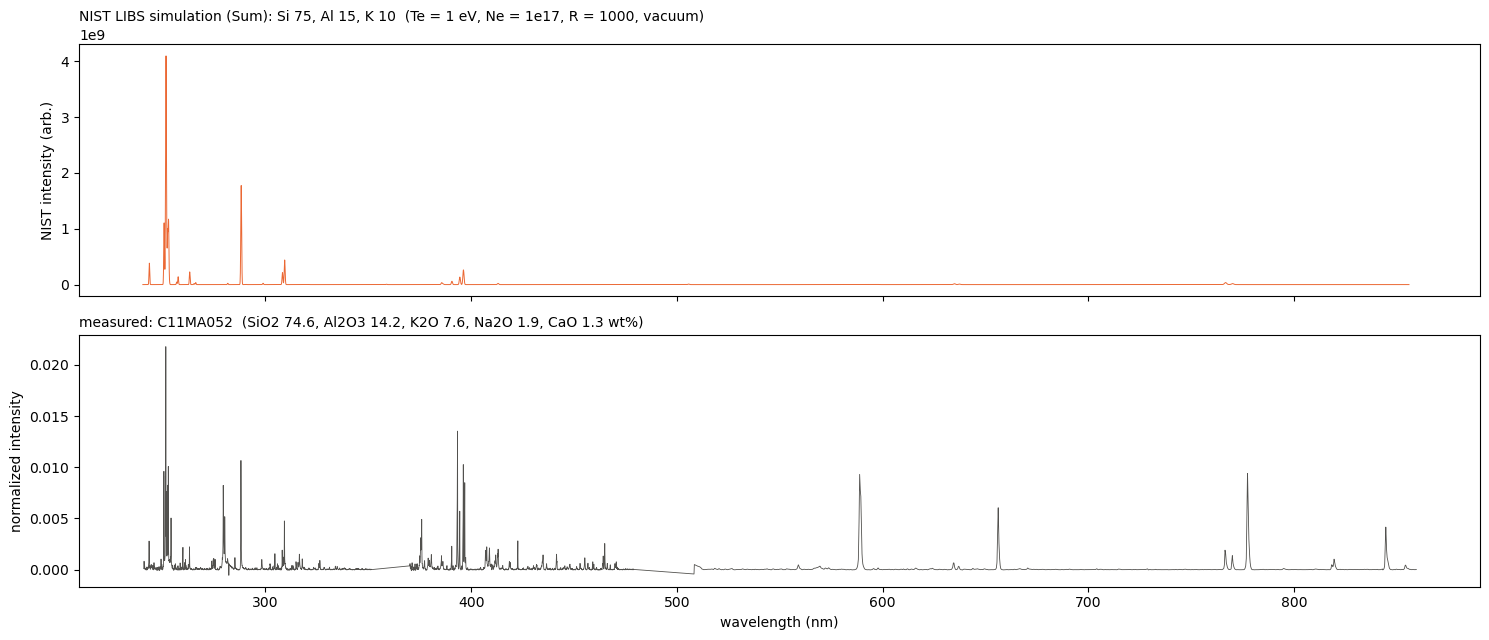

In [22]:
nist = pd.read_csv('NIST/Si75_Al15_K10.csv')
nistWl = nist['Wavelength (nm)'].values
nistSum = nist['Sum'].values

pellet = 'C11MA052'
row = df_no_outlier.index[df_no_outlier['Pellet Name'] == pellet][0]
wl = np.array(wavelength_cols, dtype=float)
measured = X[row]
comp = df_no_outlier.loc[row, ELEMENTS]

fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)

axes[0].plot(nistWl, nistSum, color='#eb6834', linewidth=0.7)
axes[0].set_title('NIST LIBS simulation (Sum): Si 75, Al 15, K 10  (Te = 1 eV, Ne = 1e17, R = 1000, vacuum)',
                  loc='left', fontsize=10)
axes[0].set_ylabel('NIST intensity (arb.)')

axes[1].plot(wl, measured, color='#52514e', linewidth=0.6)
axes[1].set_title(f'measured: {pellet}  (SiO2 {comp.SiO2:.1f}, Al2O3 {comp.Al2O3:.1f}, '
                  f'K2O {comp.K2O:.1f}, Na2O {comp.Na2O:.1f}, CaO {comp.CaO:.1f} wt%)', loc='left', fontsize=10)
axes[1].set_ylabel('normalized intensity')
axes[1].set_xlabel('wavelength (nm)')

plt.tight_layout()
plt.show()

Altering NIST so it has same x axis and normalization

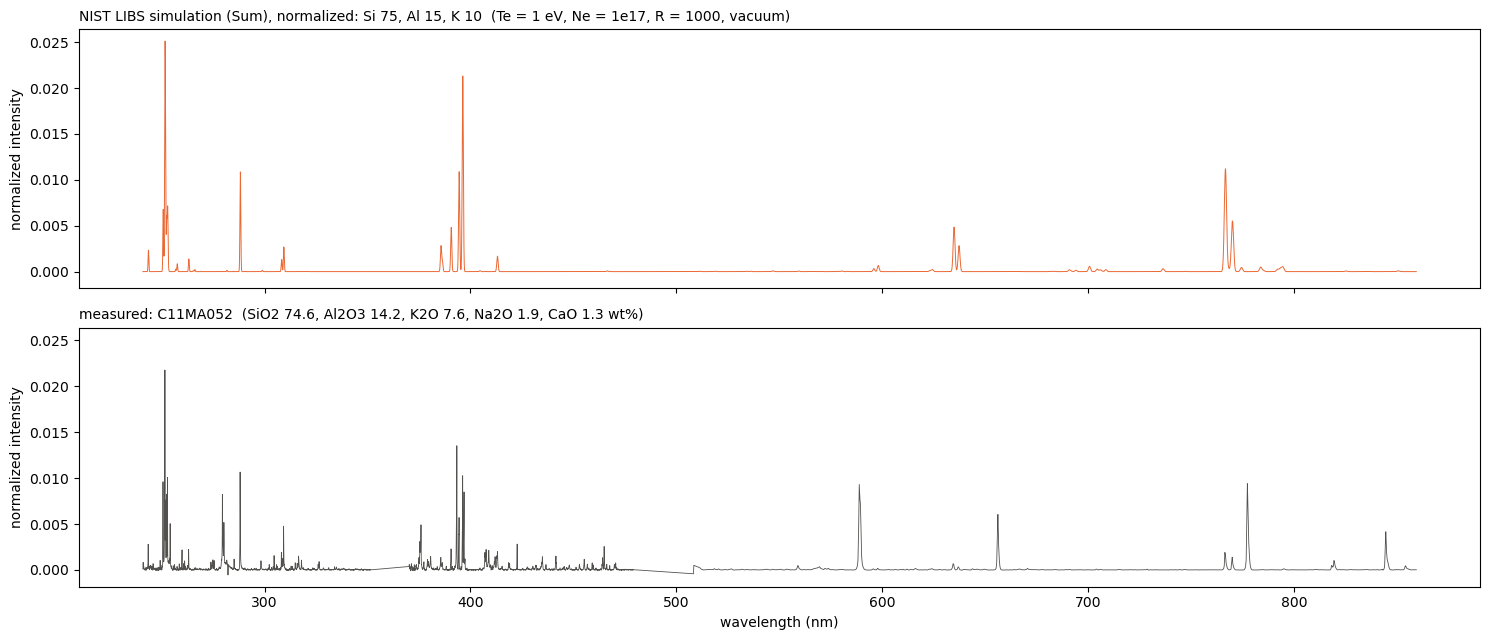

In [24]:
nist = pd.read_csv('NIST/Si75_Al15_K10.csv')
wl = np.array(wavelength_cols, dtype=float)

#making nist have same x axis
nistOnGrid = np.interp(wl, nist['Wavelength (nm)'].values, nist['Sum'].values, left=0, right=0)

#putting nist thru same normalization
nistNorm = normalize_spectra(pd.DataFrame([nistOnGrid], columns=wavelength_cols)).values[0]

pellet = 'C11MA052'
row = df_no_outlier.index[df_no_outlier['Pellet Name'] == pellet][0]
measured = X[row]
comp = df_no_outlier.loc[row, ELEMENTS]

fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, sharey=True)

axes[0].plot(wl, nistNorm, color='#eb6834', linewidth=0.7)
axes[0].set_title('NIST LIBS simulation (Sum), normalized: Si 75, Al 15, K 10  (Te = 1 eV, Ne = 1e17, R = 1000, vacuum)',
                  loc='left', fontsize=10)
axes[0].set_ylabel('normalized intensity')

axes[1].plot(wl, measured, color='#52514e', linewidth=0.6)
axes[1].set_title(f'measured: {pellet}  (SiO2 {comp.SiO2:.1f}, Al2O3 {comp.Al2O3:.1f}, '
                  f'K2O {comp.K2O:.1f}, Na2O {comp.Na2O:.1f}, CaO {comp.CaO:.1f} wt%)', loc='left', fontsize=10)
axes[1].set_ylabel('normalized intensity')
axes[1].set_xlabel('wavelength (nm)')

plt.tight_layout()
plt.show()

## Doing same analaysis for sample that's mainly Si

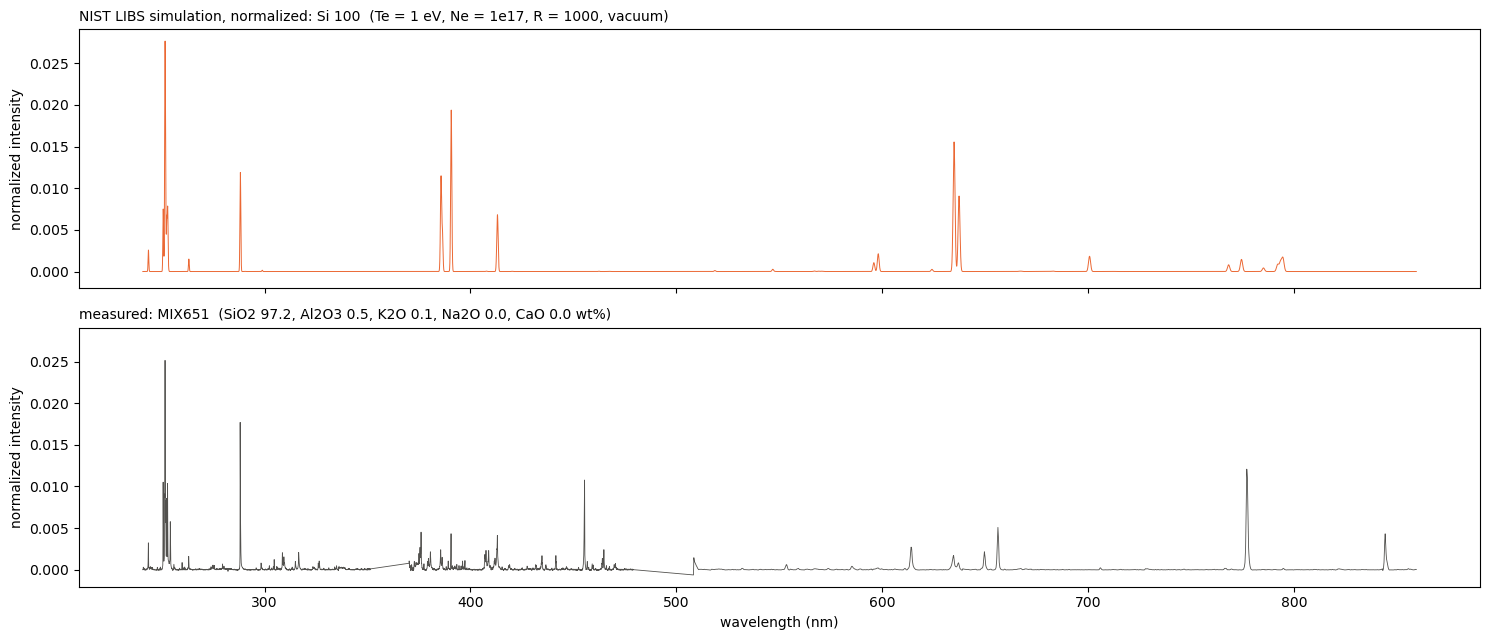

In [26]:
nist = pd.read_csv('NIST/Si100.csv')
wl = np.array(wavelength_cols, dtype=float)

#making nist have same x axis
nistOnGrid = np.interp(wl, nist.iloc[:, 0].values, nist.iloc[:, 1].values, left=0, right=0)

#putting nist thru same normalization
nistNorm = normalize_spectra(pd.DataFrame([nistOnGrid], columns=wavelength_cols)).values[0]

pellet = 'MIX651'
row = df_no_outlier.index[df_no_outlier['Pellet Name'] == pellet][0]
measured = X[row]
comp = df_no_outlier.loc[row, ELEMENTS]

fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, sharey=True)

axes[0].plot(wl, nistNorm, color='#eb6834', linewidth=0.7)
axes[0].set_title('NIST LIBS simulation, normalized: Si 100  (Te = 1 eV, Ne = 1e17, R = 1000, vacuum)',
                  loc='left', fontsize=10)
axes[0].set_ylabel('normalized intensity')

axes[1].plot(wl, measured, color='#52514e', linewidth=0.6)
axes[1].set_title(f'measured: {pellet}  (SiO2 {comp.SiO2:.1f}, Al2O3 {comp.Al2O3:.1f}, '
                  f'K2O {comp.K2O:.1f}, Na2O {comp.Na2O:.1f}, CaO {comp.CaO:.1f} wt%)', loc='left', fontsize=10)
axes[1].set_ylabel('normalized intensity')
axes[1].set_xlabel('wavelength (nm)')

plt.tight_layout()
plt.show()

## Plotting all the NIST for 100% to determine where the mask should be individually

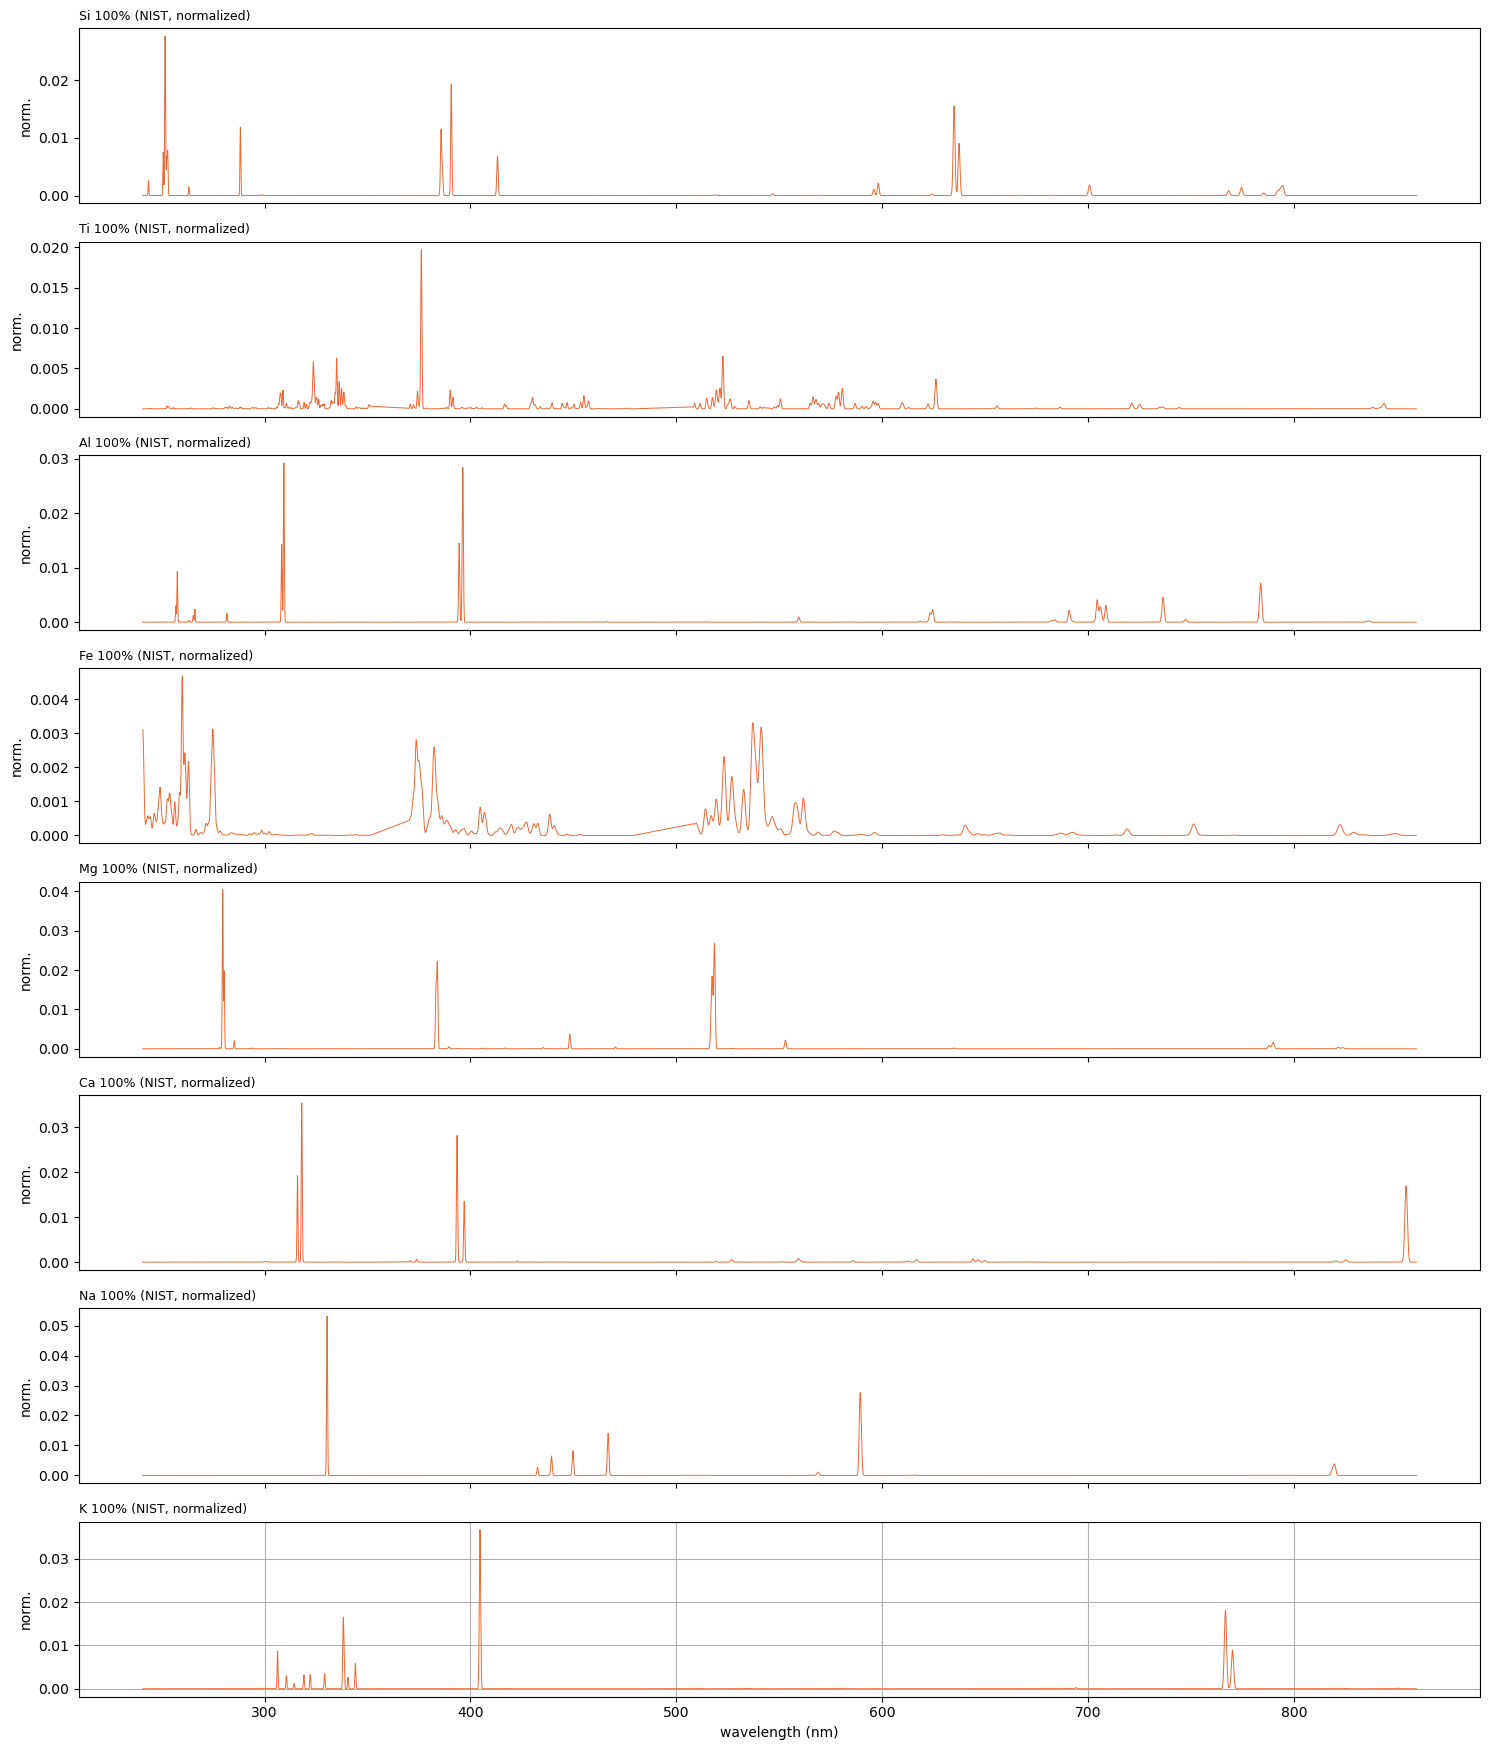

In [28]:
elements = ['Si', 'Ti', 'Al', 'Fe', 'Mg', 'Ca', 'Na', 'K']
wl = np.array(wavelength_cols, dtype=float)

fig, axes = plt.subplots(len(elements), 1, figsize=(15, 2.2 * len(elements)), sharex=True)

for ax, el in zip(axes, elements):
    nist = pd.read_csv(f'NIST/{el}100.csv')
    onGrid = np.interp(wl, nist.iloc[:, 0].values, nist.iloc[:, 1].values, left=0, right=0)
    norm = normalize_spectra(pd.DataFrame([onGrid], columns=wavelength_cols)).values[0]
    norm = np.nan_to_num(norm)

    ax.plot(wl, norm, color='#eb6834', linewidth=0.7)
    ax.set_title(f'{el} 100% (NIST, normalized)', loc='left', fontsize=9)
    ax.set_ylabel('norm.')

axes[-1].set_xlabel('wavelength (nm)')
plt.tight_layout()
plt.grid()
plt.show()

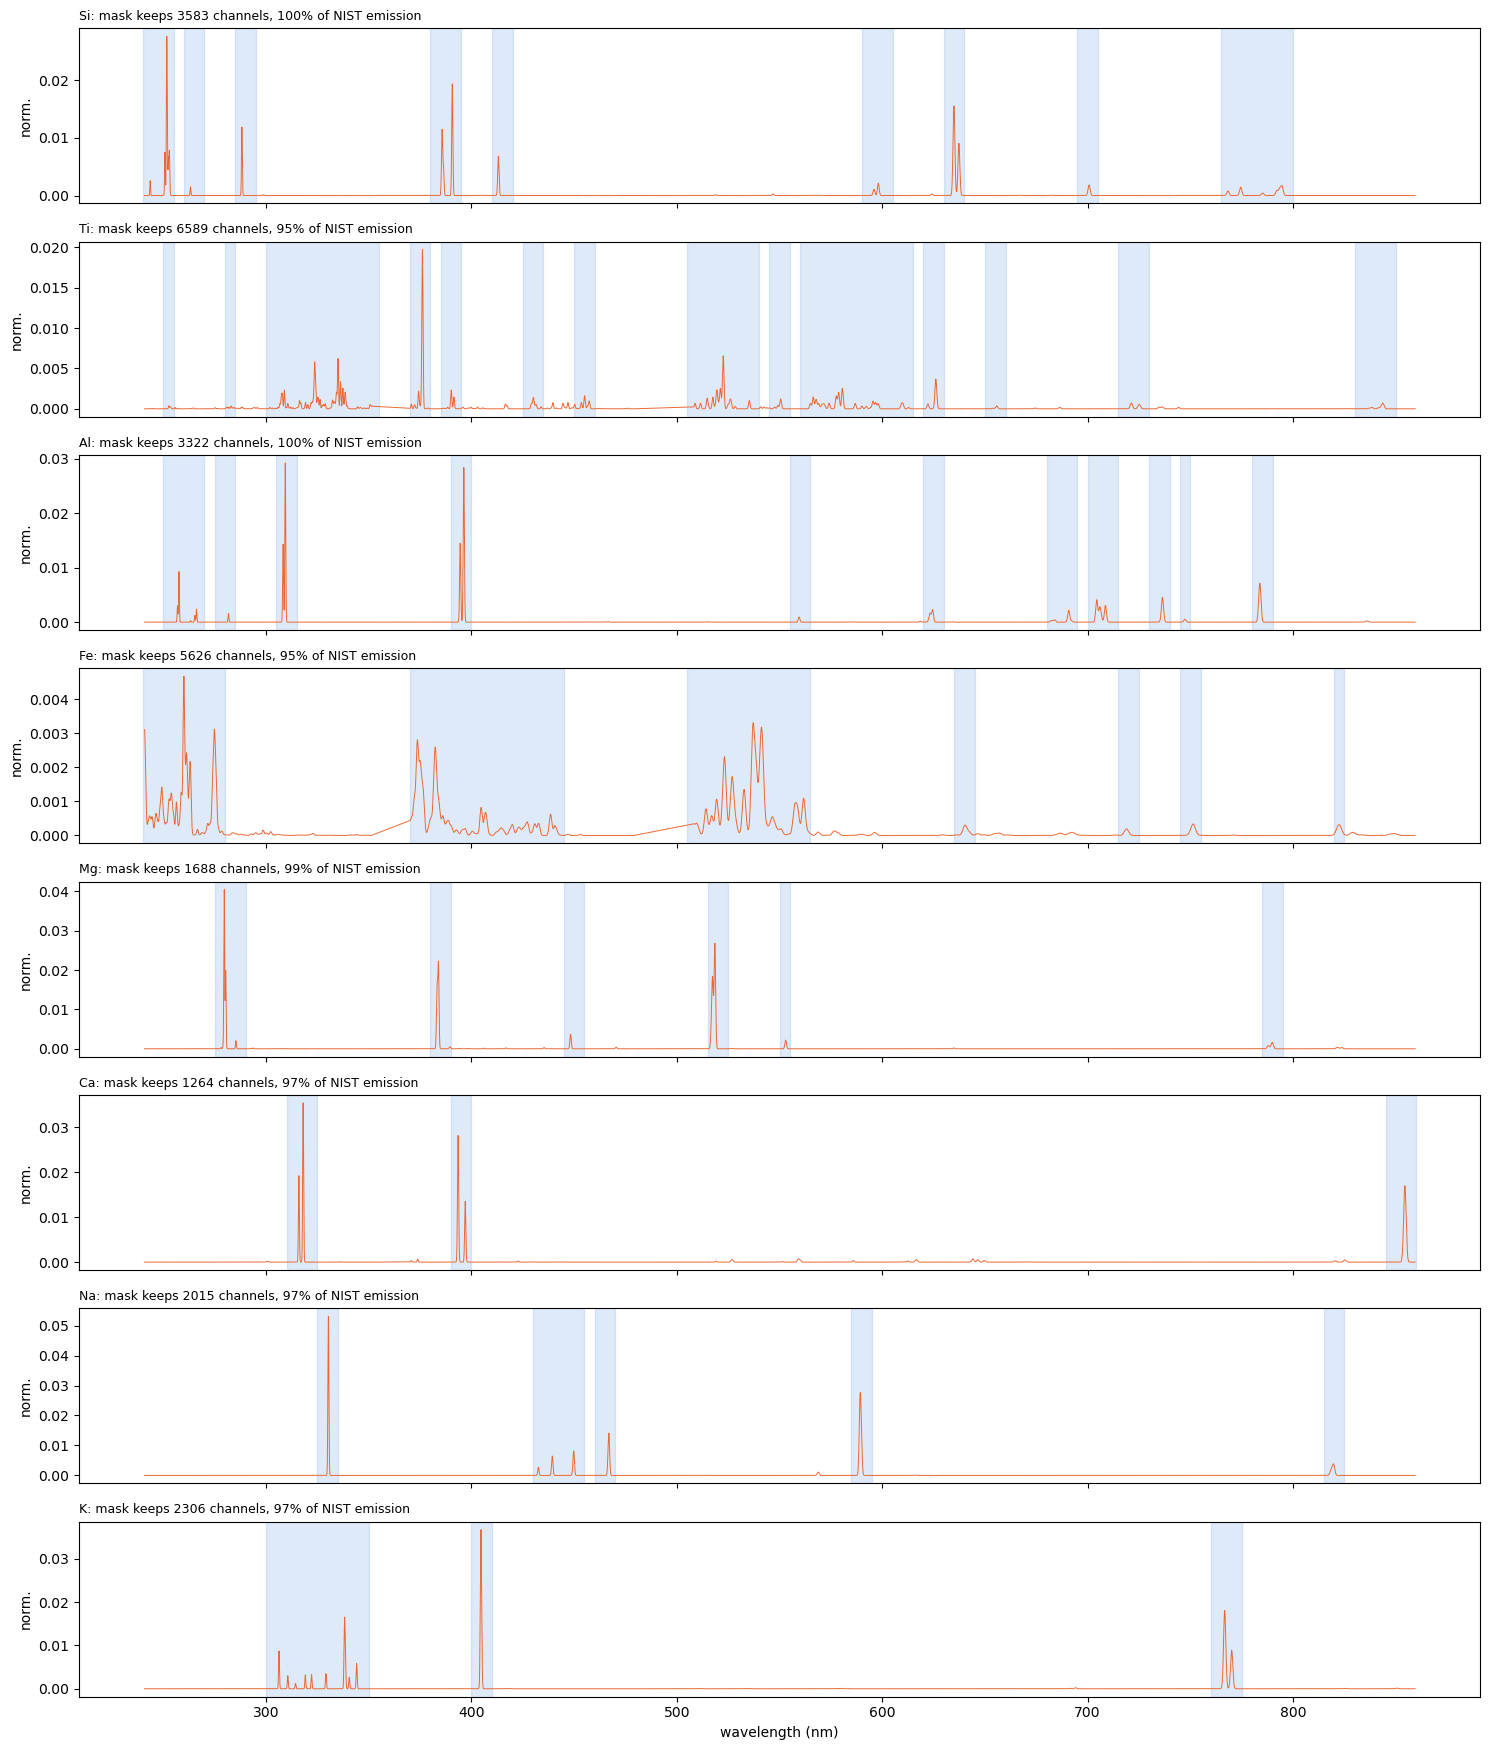

In [31]:
MASKS = {
    'Si': [(240, 255), (260, 270), (285, 295), (380, 395), (410, 420), (590, 605), (630, 640), (695, 705), (765, 800)],
    'Ti': [(250, 255), (280, 285), (300, 355), (370, 380), (385, 395), (425, 435), (450, 460), (505, 540), (545, 555), (560, 615), (620, 630), (650, 660), (715, 730), (830, 850)],
    'Al': [(250, 270), (275, 285), (305, 315), (390, 400), (555, 565), (620, 630), (680, 695), (700, 715), (730, 740), (745, 750), (780, 790)],
    'Fe': [(240, 280), (370, 445), (505, 565), (635, 645), (715, 725), (745, 755), (820, 825)],
    'Mg': [(275, 290), (380, 390), (445, 455), (515, 525), (550, 555), (785, 795)],
    'Ca': [(310, 325), (390, 400), (845, 860)],
    'Na': [(325, 335), (430, 455), (460, 470), (585, 595), (815, 825)],
    'K':  [(300, 350), (400, 410), (760, 775)],
}

elements = list(MASKS)
wl = np.array(wavelength_cols, dtype=float)
inMask = {}

fig, axes = plt.subplots(len(elements), 1, figsize=(15, 2.2 * len(elements)), sharex=True)

for ax, el in zip(axes, elements):
    nist = pd.read_csv(f'NIST/{el}100.csv')
    onGrid = np.interp(wl, nist.iloc[:, 0].values, nist.iloc[:, 1].values, left=0, right=0)
    norm = np.nan_to_num(normalize_spectra(pd.DataFrame([onGrid], columns=wavelength_cols)).values[0])

    keep = np.zeros(len(wl), dtype=bool)
    for lo, hi in MASKS[el]:
        keep = keep | ((wl >= lo) & (wl <= hi))
        ax.axvspan(lo, hi, color='#2a78d6', alpha=0.15)
    inMask[el] = keep

    captured = onGrid[keep].sum() / onGrid.sum() * 100
    ax.plot(wl, norm, color='#eb6834', linewidth=0.7)
    ax.set_title(f'{el}: mask keeps {keep.sum()} channels, {captured:.0f}% of NIST emission',
                 loc='left', fontsize=9)
    ax.set_ylabel('norm.')

axes[-1].set_xlabel('wavelength (nm)')
plt.tight_layout()
plt.show()

combined mask keeps 13500 of 15498 channels (87%)
combined ranges: [(240, 295), (300, 355), (370, 470), (505, 615), (620, 645), (650, 660), (680, 740), (745, 755), (760, 800), (815, 825), (830, 860)]


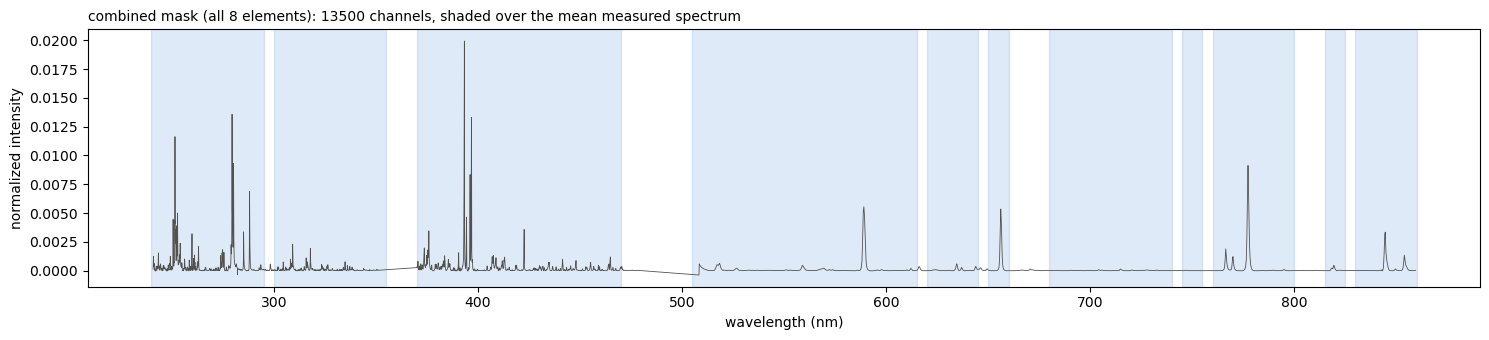

In [32]:
allMask = np.zeros(len(wl), dtype=bool)
for el in MASKS:
    allMask = allMask | inMask[el]
inMask['ALL'] = allMask

allRanges = []
for lo, hi in sorted(r for ranges in MASKS.values() for r in ranges):
    if allRanges and lo <= allRanges[-1][1]:
        allRanges[-1] = (allRanges[-1][0], max(allRanges[-1][1], hi))
    else:
        allRanges.append((lo, hi))

print('combined mask keeps', allMask.sum(), 'of', len(wl), f'channels ({allMask.mean() * 100:.0f}%)')
print('combined ranges:', allRanges)

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.plot(wl, X.mean(axis=0), color='#52514e', linewidth=0.6)
for lo, hi in allRanges:
    ax.axvspan(lo, hi, color='#2a78d6', alpha=0.15)
ax.set_title(f'combined mask (all 8 elements): {allMask.sum()} channels, shaded over the mean measured spectrum',
             loc='left', fontsize=10)
ax.set_xlabel('wavelength (nm)')
ax.set_ylabel('normalized intensity')
plt.tight_layout()
plt.show()